# 02. ML in papers and AI-ready data on platforms

**Goal.** Place the geosciences against other fields on three platform-level measures: how often papers mention ML, how often registered datasets mention ML or call themselves AI-ready, and how many dataset repositories exist on Hugging Face.

**Inputs.** `docs/archive_readiness_2026-10-30/platform_counts.json` (93 keyless requests to DataCite, Hugging Face and OpenAlex on 2026-10-30) with every response hashed in `platform_receipts.json`. Producer: `scripts/platform_readiness_counts.py`.

**Reproducibility.** `scripts/requery_check.py` re-runs the same query builders live and compares every number with the frozen file. This notebook runs it offline by default; set `READINESS_LIVE=1` before executing to re-query.

In [1]:
import json, csv, hashlib, os, subprocess, sys
from collections import Counter, defaultdict
from pathlib import Path
from IPython.display import Image, Markdown, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pixi.toml").exists())
sys.path.insert(0, str(ROOT / "tools"))
def table(header, rows):
    """Render rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))
print("repository root:", ROOT)

repository root: /Users/marinedenolle/GitHub/geoscience-ai-readiness


## 1. The exact queries

All counts are keyword or metadata matches, never actual use. These strings are imported from the collector, so the notebook and the script cannot drift apart.

In [2]:
import importlib.util
spec = importlib.util.spec_from_file_location("prc", ROOT / "scripts/platform_readiness_counts.py")
prc = importlib.util.module_from_spec(spec); spec.loader.exec_module(prc)
table(["Name", "Query"], [["AI-ready", prc.AI_READY], ["ML", prc.ML], ["Earth subject tag (DataCite)", prc.EARTH_FOS],
                          ["Simulation method", prc.SIM], ["ML surrogate", prc.SURR_ML]] +
      [[f"DataCite: {k}", v] for k, v in prc.DISCIPLINES.items()])
print("OpenAlex fields used for Earth and environmental sciences:", prc.OPENALEX_FIELDS)

| Name | Query |
|---|---|
| AI-ready | ("AI-ready" OR "AI ready" OR "ML-ready" OR "ML ready" OR "machine learning ready" OR "machine-learning-ready") |
| ML | ("machine learning" OR "deep learning" OR "neural network") |
| Earth subject tag (DataCite) | subjects.subject:"FOS: Earth and related environmental sciences" |
| Simulation method | ("numerical simulation" OR "finite element" OR "finite difference" OR "spectral element" OR "finite volume") |
| ML surrogate | ("physics-informed neural network" OR "neural operator" OR DeepONet OR (("surrogate model" OR emulator) AND ("machine learning" OR "deep learning" OR "neural network"))) |
| DataCite: seismology | (seismic OR seismology OR earthquake OR "distributed acoustic sensing") |
| DataCite: geodesy_sar | (InSAR OR GNSS OR geodetic OR "synthetic aperture radar") |
| DataCite: optical_remote_sensing | ("remote sensing" OR Landsat OR "Sentinel-2" OR multispectral OR hyperspectral) |
| DataCite: weather_climate | (weather OR climate OR reanalysis OR ERA5 OR CMIP6) |
| DataCite: hydrology | (hydrology OR streamflow OR groundwater OR "soil moisture") |
| DataCite: ocean | (oceanography OR "sea surface" OR Argo OR "ocean model") |
| DataCite: biomedicine | (clinical OR medical OR patient OR genomics) |
| DataCite: materials_chemistry | (materials OR molecule OR "crystal structure") |

OpenAlex fields used for Earth and environmental sciences: {'earth_planetary': 'fields/19', 'environmental': 'fields/23'}


## 2. ML mentions in articles, all fields against Earth and environmental sciences

In [3]:
counts = json.loads((ROOT / "docs/archive_readiness_2026-10-30/platform_counts.json").read_text())
o = counts["openalex"]
rows = []
for y in sorted(o["works_all_by_year"]):
    share = lambda k: 100 * o[f"ml_works_{k}_by_year"][y]["count"] / o[f"works_{k}_by_year"][y]["count"]
    rows.append([y, f'{o["works_all_by_year"][y]["count"]:,}', f'{share("all"):.2f}%', f'{o["works_earth_env_by_year"][y]["count"]:,}', f'{share("earth_env"):.2f}%'])
table(["Year", "All articles", "ML share", "Earth + env articles", "ML share"], rows)

| Year | All articles | ML share | Earth + env articles | ML share |
|---|---|---|---|---|
| 2016 | 6,356,228 | 0.35% | 367,157 | 0.42% |
| 2017 | 6,015,168 | 0.48% | 342,548 | 0.55% |
| 2018 | 5,897,387 | 0.74% | 339,678 | 0.77% |
| 2019 | 6,145,030 | 1.07% | 345,159 | 1.10% |
| 2020 | 6,426,598 | 1.42% | 349,579 | 1.56% |
| 2021 | 5,961,451 | 1.96% | 335,304 | 2.16% |
| 2022 | 5,521,397 | 2.54% | 313,462 | 2.89% |
| 2023 | 5,766,766 | 2.87% | 320,699 | 3.38% |
| 2024 | 6,204,408 | 3.42% | 351,719 | 4.09% |
| 2025 | 7,172,668 | 3.89% | 397,794 | 5.11% |

## 3. Registered datasets (DataCite) and AI-native hub (Hugging Face)

In [4]:
d, h = counts["datacite"], counts["hf"]
print(f'DataCite datasets: {d["all_datasets"]:,}; mention ML: {d["ml_all"]:,}; say AI- or ML-ready: {d["ai_ready_all"]}')
print("AI-ready datasets by publication year:", d["ai_ready_all_by_year"])
rows = [[k, f'{v["datasets"]:,}', f'{v["mention_ml"]:,}', f'{100*v["mention_ml"]/v["datasets"]:.1f}%', v["mention_ai_ready"],
         f'{(25 if k == "geodesy_sar" else h[k]["datasets"]):,}'] for k, v in d["disciplines"].items()]
table(["Keyword set", "DataCite datasets", "Mention ML", "Share", "AI-ready", "Hugging Face repos"], rows)
print("Hugging Face geodesy/SAR keeps only 'insar' and 'gnss' id matches; 'sar-' and 'geodes' matched unrelated repositories.")

DataCite datasets: 78,241,222; mention ML: 666,883; say AI- or ML-ready: 707
AI-ready datasets by publication year: {'2016': 0, '2017': 0, '2018': 0, '2019': 0, '2020': 5, '2021': 0, '2022': 13, '2023': 27, '2024': 50, '2025': 156}


| Keyword set | DataCite datasets | Mention ML | Share | AI-ready | Hugging Face repos |
|---|---|---|---|---|---|
| seismology | 43,477 | 1,126 | 2.6% | 12 | 393 |
| geodesy_sar | 52,497 | 768 | 1.5% | 7 | 25 |
| optical_remote_sensing | 82,789 | 8,552 | 10.3% | 81 | 554 |
| weather_climate | 322,903 | 7,167 | 2.2% | 69 | 1,399 |
| hydrology | 54,846 | 2,089 | 3.8% | 12 | 1,109 |
| ocean | 148,653 | 1,120 | 0.8% | 10 | 510 |
| biomedicine | 453,674 | 12,551 | 2.8% | 90 | 4,624 |
| materials_chemistry | 1,811,379 | 8,504 | 0.5% | 85 | 871 |

Hugging Face geodesy/SAR keeps only 'insar' and 'gnss' id matches; 'sar-' and 'geodes' matched unrelated repositories.


## 4. Figures

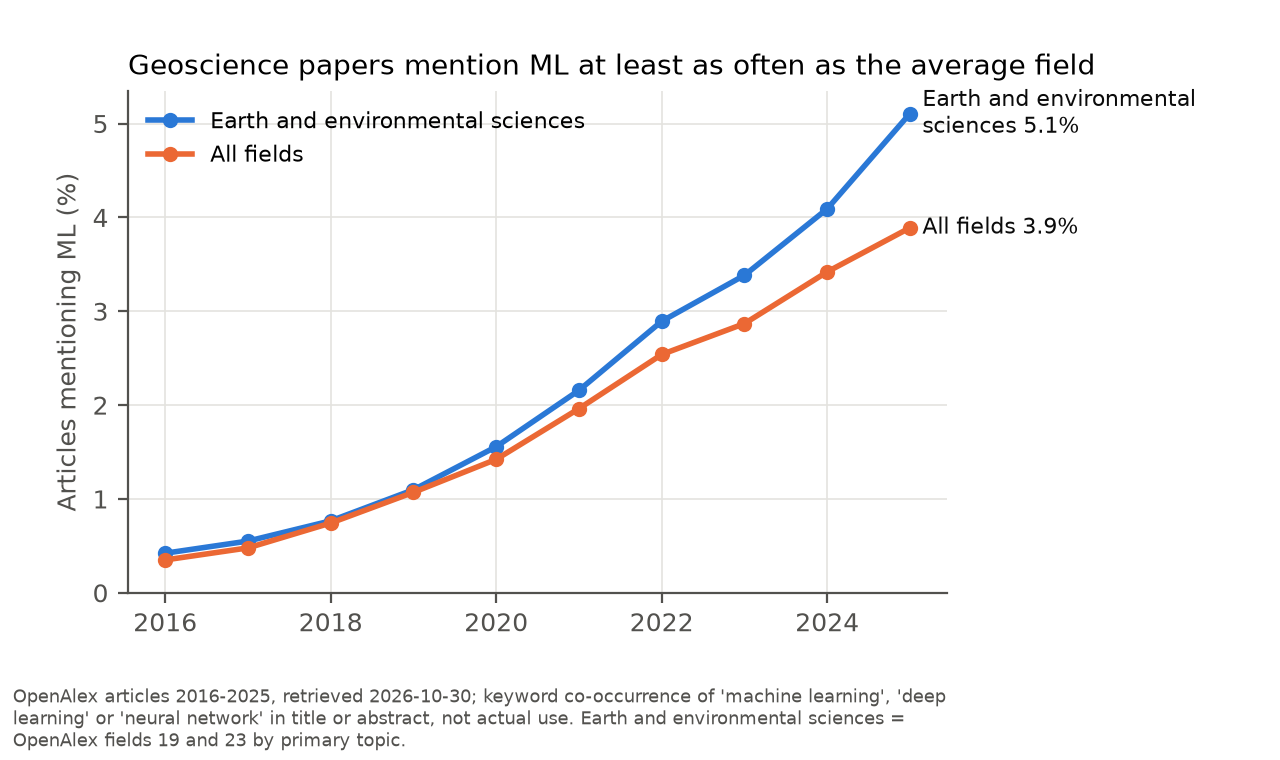

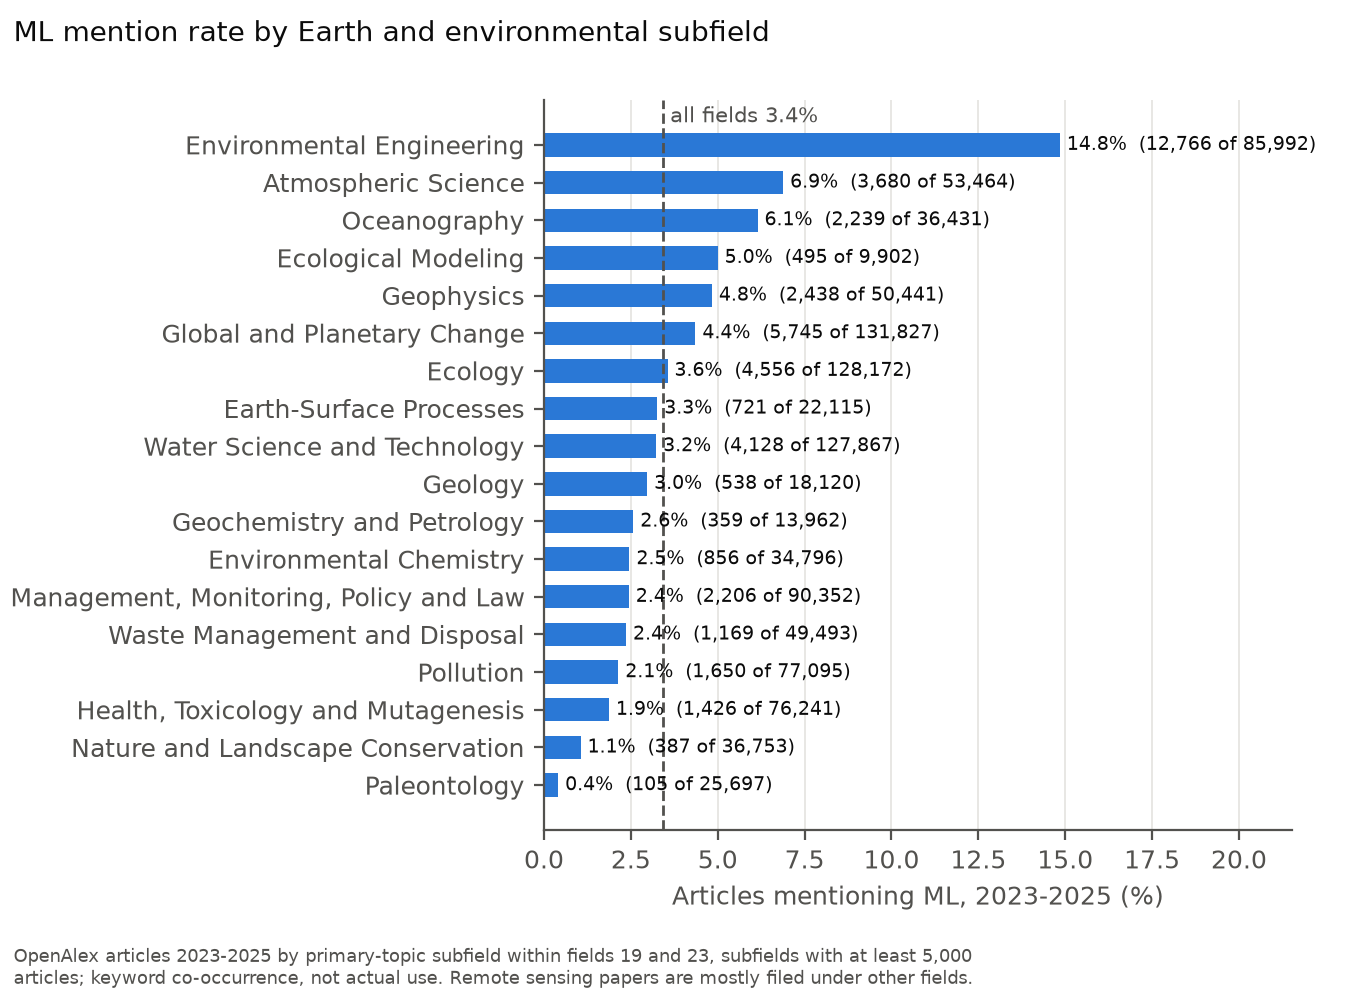

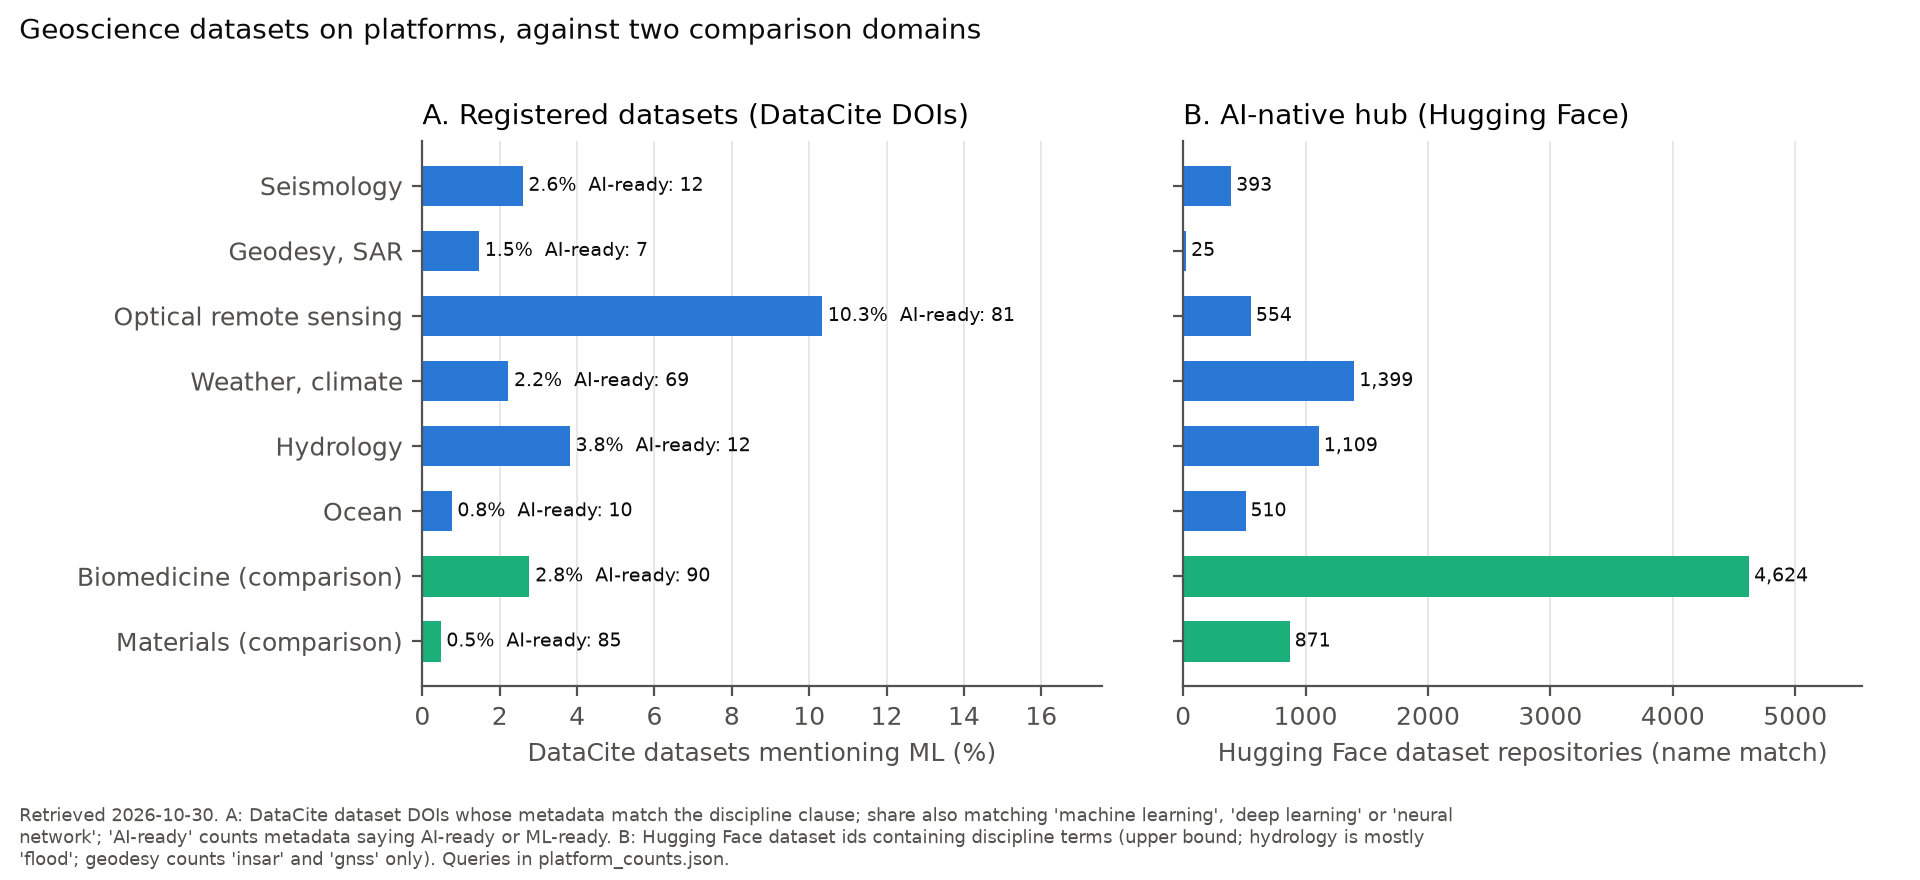

In [5]:
subprocess.run([sys.executable, str(ROOT / "scripts/archive_readiness_figures.py")], check=True, cwd=ROOT, capture_output=True)
for name in ("fig2_ml_share_by_year", "fig3_ml_share_by_subfield", "fig4_platform_datasets"):
    display(Image(filename=str(ROOT / "build/archive_readiness" / f"{name}.png"), width=760))

## 5. Reproducibility check

Offline: every frozen snapshot must match its manifest hash. Live (opt-in): re-query and compare. The receipt of the 2026-10-30 live re-query is committed as `docs/archive_readiness_2026-10-30/requery_2026-10-30.md`.

In [6]:
r = subprocess.run([sys.executable, str(ROOT / "scripts/requery_check.py"), "--offline"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout)
if os.environ.get("READINESS_LIVE") == "1":
    from datetime import date
    out = ROOT / "runs" / f"requery_{date.today().isoformat()}_nb"
    r = subprocess.run([sys.executable, str(ROOT / "scripts/requery_check.py"), "--out", str(out)], cwd=ROOT, capture_output=True, text=True)
    display(Markdown(r.stdout.split("# Re-query check", 1)[-1]))
else:
    text = (ROOT / "docs/archive_readiness_2026-10-30/requery_2026-10-30.md").read_text()
    display(Markdown("Committed receipt (first sections):\n\n" + "\n".join(text.splitlines()[:22])))

{
  "frozen_files": 12,
  "matching": 12
}



Committed receipt (first sections):

# Re-query check, 2026-10-30T12:19:58+00:00

## Frozen-file hashes

12 of 12 frozen files match their manifests.

## DAS title/abstract counts per year (Fig. 2B input)

| Year | Frozen 2026-10-21 | Live |
|---|---|---|
| 2020 | 118 | 118 |
| 2021 | 137 | 137 |
| 2022 | 194 | 194 |
| 2023 | 238 | 238 |
| 2024 | 311 | 312 |
| 2025 | 424 | 425 |

## openalex

90 numbers compared; 90 within 1%, 90 within 5%, 90 within 20%.

| Largest changes | Frozen | Live | Change |